# Setup

In [1]:
import os
import subprocess
import time
from pathlib import Path


def setup_headless_vtk(
    width=1920,
    height=1080,
    depth=24,
    start_display=90,
    end_display=200,
):
    """
    Start a private Xvfb server and configure VTK/PyVista
    for software rendering on HPC systems.
    """

    # If a valid DISPLAY already exists, keep it
    if os.environ.get("DISPLAY"):
        print(f"Using existing DISPLAY={os.environ['DISPLAY']}")
        return os.environ["DISPLAY"]

    # Find an unused display number
    display_num = None

    for d in range(start_display, end_display):
        lock_file = Path(f"/tmp/.X{d}-lock")

        if lock_file.exists():
            continue

        proc = subprocess.Popen(
            [
                "Xvfb",
                f":{d}",
                "-screen",
                "0",
                f"{width}x{height}x{depth}",
            ],
            stdout=subprocess.DEVNULL,
            stderr=subprocess.DEVNULL,
        )

        # Give Xvfb a moment to start
        time.sleep(1)

        if proc.poll() is None:
            display_num = d
            break

    if display_num is None:
        raise RuntimeError("Could not find a free X display")

    display = f":{display_num}"

    # Configure rendering environment
    os.environ["DISPLAY"] = display
    os.environ["VTK_DEFAULT_OPENGL_WINDOW"] = "vtkXOpenGLRenderWindow"
    os.environ["LIBGL_ALWAYS_SOFTWARE"] = "1"
    os.environ["MESA_LOADER_DRIVER_OVERRIDE"] = "llvmpipe"

    print(f"Started Xvfb on DISPLAY={display}")

    return display

setup_headless_vtk()

Started Xvfb on DISPLAY=:90


':90'

In [2]:
import pyvista as pv
import mne


# pv.set_jupyter_backend("html")
# mne.viz.set_3d_backend("notebook")

pv.set_jupyter_backend("trame")
mne.viz.set_3d_backend("notebook")

import matplotlib.pyplot as plt


Using notebook 3d backend.


In [3]:
from mri import plot_subj, plot_subjs_on_avg

## ROI selection functions

In [4]:
from ieeg.io import raw_from_layout
from bids.layout import BIDSLayout
import mne

def load_raw(bids_layout, subject, preload=False, **kwargs):
    # search query
    raw = raw_from_layout(
        bids_layout,
        subject=subject,
        extension='.edf',
        scope='raw',
        preload=preload,
        **kwargs
    )

    # check the raw data was found with query
    if not raw:
        raise ValueError(f'No raw data found for subject: {subject}')

    if preload:
        if not raw.preload and preload:
            raw.load_data()
        raw._data *= 1e6  # convert to uV

    # remove Trigger channel we have any
    raw.drop_channels(['Trigger']) if 'Trigger' in raw.ch_names else None

    return raw

def load_derivative_raw(bids_layout, subject, derivative_name='phonemeLevel',
                        desc='phonemeLevel', **kwargs):
    """Load a raw recording from a BIDS derivatives subdirectory.

    Parameters
    ----------
    bids_layout : BIDSLayout
        The BIDS layout object, initialized with ``derivatives=True``.
    subject : str
        The subject identifier (without 'sub-' prefix).
    derivative_name : str
        Name of the derivative dataset under ``derivatives/``.
    desc : str
        The ``desc`` entity used in derivative filenames.
    **kwargs
        Additional keyword arguments passed to ``raw_from_layout``.
    """
    deriv_key = f'derivatives/{derivative_name}'
    deriv_layout = bids_layout.derivatives[deriv_key]
    raw = raw_from_layout(
        deriv_layout, subject=subject, extension='.edf',
        desc=desc, **kwargs
    )
    if not raw:
        raise ValueError(
            f'No derivative raw for {subject} in {derivative_name}')

    raw.load_data()
    raw._data *= 1e6  # convert to uV

    raw.drop_channels(['Trigger']) if 'Trigger' in raw.ch_names else None

    return raw

In [5]:
def get_electrodes_in_roi(labels, roi_labels):
    return [
        ch_name
        for ch_name, roi_list in labels.items()
        if roi_labels.intersection(roi_list)
    ]

# Broad superior temporal auditory ROI
auditory_base = {
    "G_temp_sup-G_T_transv",
    "G_temp_sup-Plan_tempo",
    "G_temp_sup-Lateral",
    "G_temp_sup-Plan_polar",
    "S_temporal_sup",
    "S_temporal_transverse",
}

auditory_roi = {
    f"ctx_{hemi}_{region}"
    for hemi in ("lh", "rh")
    for region in auditory_base
}

# Core sensorimotor ROI
sensorimotor_core_base = {
    "G_precentral",
    "G_postcentral",
    "S_central",
}

sensorimotor_core_roi = {
    f"ctx_{hemi}_{region}"
    for hemi in ("lh", "rh")
    for region in sensorimotor_core_base
}

# Extended sensorimotor ROI
sensorimotor_extended_base = sensorimotor_core_base | {
    "S_precentral-inf-part",
    "S_precentral-sup-part",
    "S_postcentral",
    "G_and_S_paracentral",
    "G_and_S_subcentral",
}

sensorimotor_extended_roi = {
    f"ctx_{hemi}_{region}"
    for hemi in ("lh", "rh")
    for region in sensorimotor_extended_base
}

# Subject-specific

## Electrode selection by ROI

In [22]:
patient = 'D0095'
bids_root = Path("~/cworkspace/BIDS-1.4_Phoneme_sequencing/BIDS/").expanduser()
recon_dir = Path("~/cworkspace/ECoG_Recon_Full/").expanduser()

bids_layout = BIDSLayout(
        root=bids_root,
        derivatives=True,
    )

# load raw
# raw = load_derivative_raw(bids_layout, patient, 'bipolar', desc='bipolar')
raw = load_raw(bids_layout, patient)

# Get electrode locations
montage = raw.get_montage()
positions = montage.get_positions()['ch_pos']
montage_mri = mne.channels.make_dig_montage(ch_pos=positions, coord_frame='mri')

# labels per electrode
labels, _ = mne.get_montage_volume_labels(
    montage_mri,
    subject=patient[0] + patient[1:].lstrip('0'),
    subjects_dir=recon_dir,
    aseg="aparc.a2009s+aseg",
    # aseg="aparc+aseg",
    dist=1
)

KeyboardInterrupt: 

In [ ]:
auditory_electrodes = get_electrodes_in_roi(
    labels, auditory_roi
)

sensorimotor_electrodes = get_electrodes_in_roi(
    labels, sensorimotor_core_roi
)

print("Auditory:", auditory_electrodes)
print("Sensorimotor:", sensorimotor_electrodes)

Auditory: ['RTAS5', 'RTAS6', 'RTAS7', 'RTAS8', 'RTAS10', 'RTPS11', 'RTPS12', 'RTPS13', 'RTPS14', 'RTPS16']
Sensorimotor: ['LFAI11', 'LFAI12', 'RFMS9', 'RFMS10', 'RFMS11', 'RFMS12', 'RFPS12', 'RPMS10', 'RPMS11', 'RPMS12', 'RPMS13', 'RPMS14', 'RPCM13', 'RPAI12', 'RPAI13', 'RPAI14', 'RPAI15']


## Brain plot

EmbeddableWidget(value='<iframe srcdoc="<!doctype html>\n<html lang=&quot;en&quot;>\n  <head>\n    <meta chars…

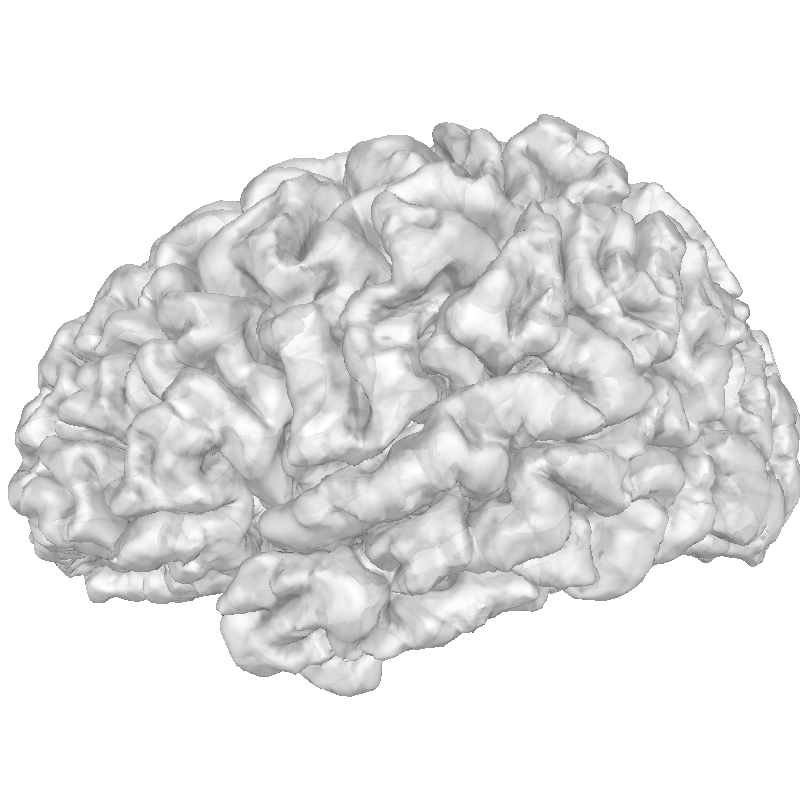

In [17]:
# brain = plot_subj(
#     'S51',
#     surface='pial',
#     subj_dir=Path("~/cworkspace/ECoG_Recon_Full/").expanduser(),
#     brain_kwargs={
#         # 'cortex': [0.900, 0.900, 0.900],
#         'cortex': [(0.9, 0.9, 0.9), (0.7, 0.7, 0.7)],
#         # 'cortex': 'ivory',
#         'alpha': 0.7,
#         'background': 'white',
#         'show': False,
#     },
#     elec_kwargs={
#         'color': 'red',
#         'scale_factor': 0.05,
#         'micro_scale_factor': 1.8,
#         'map_surface': None},
# )
brain = plot_subj(
    'D0095',
    subj_dir=Path("~/cworkspace/ECoG_Recon_Full/").expanduser(),
    bids_root=Path("~/cworkspace/BIDS-1.4_Phoneme_sequencing/BIDS/").expanduser(),
    surface='pial',
    # picks=sensorimotor_electrodes,
    picks=auditory_electrodes,
    brain_kwargs={
        # 'cortex': [0.900, 0.900, 0.900],
        'cortex': [(0.9, 0.9, 0.9), (0.7, 0.7, 0.7)],
        # 'cortex': 'high_contrast',
        # 'cortex': 'ivory',
        'alpha': 0.8,
        'background': 'white',
        'show': False,
    },
    elec_kwargs={
        'color': 'red',
        'scale_factor': 0.5,
        'map_surface': None},
)
brain.show_view('lateral', hemi='lh')
brain._renderer.plotter.show(jupyter_backend='html')
brain._renderer.plotter.show(jupyter_backend='notebook')

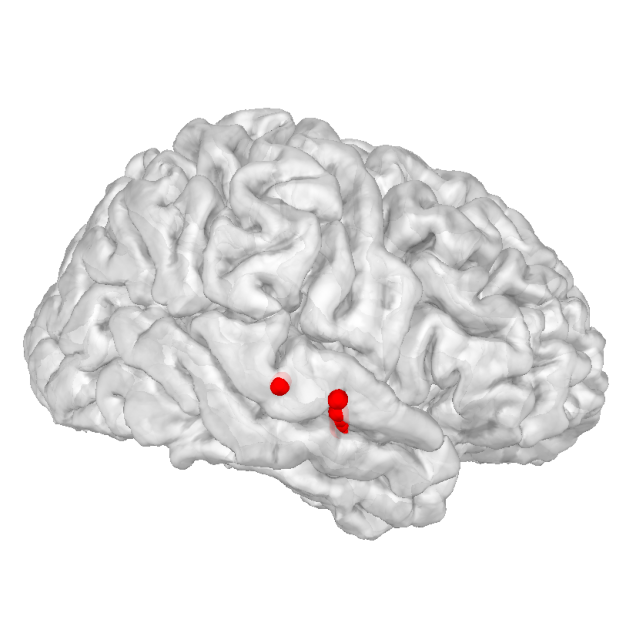

In [ ]:
# # brain.show_view('frontal', azimuth=95, elevation=95)
# brain.show_view('lateral', hemi='rh')
# img = brain.screenshot()

# fig = plt.figure(figsize=(8,8))
# ax = fig.add_subplot(111)
# ax.imshow(img)
# ax.axis('off')

# plt.show()

# On average subject

## Electrode selection by ROI

In [8]:
subjects = ['D0028', 'D0040', 'D0042', 'D0049', 'D0052', 'D0055', 'D0064', 'D0068', 'D0069', 'D0075', 'D0079', 'D0084', 'D0092', 'D0095', 'D0096']
bids_root = Path("~/cworkspace/BIDS-1.4_Phoneme_sequencing/BIDS/").expanduser()
recon_dir = Path("~/cworkspace/ECoG_Recon_Full/").expanduser()

bids_layout = BIDSLayout(
        root=bids_root,
        derivatives=True,
    )

aud_picks = {}
smc_picks = {}
for subj in subjects:
    # load raw
    # raw = load_derivative_raw(bids_layout, patient, 'bipolar', desc='bipolar')
    raw = load_raw(bids_layout, subj, preload=False, verbose='CRITICAL')

    # Get electrode locations
    montage = raw.get_montage()
    positions = montage.get_positions()['ch_pos']
    montage_mri = mne.channels.make_dig_montage(ch_pos=positions, coord_frame='mri')

    # labels per electrode
    labels, _ = mne.get_montage_volume_labels(
        montage_mri,
        subject=subj[0] + subj[1:].lstrip('0'),
        subjects_dir=recon_dir,
        aseg="aparc.a2009s+aseg",
        # aseg="aparc+aseg",
        dist=1
    )

    auditory_electrodes = get_electrodes_in_roi(
        labels, auditory_roi
    )

    sensorimotor_electrodes = get_electrodes_in_roi(
        labels, sensorimotor_core_roi
    )

    aud_picks[subj] = auditory_electrodes
    smc_picks[subj] = sensorimotor_electrodes

    print(f"Subject: {subj}")
    print("    Auditory:", auditory_electrodes)
    print("    Sensorimotor:", sensorimotor_electrodes)

aud_picks_list = [f"{subj[0]+subj[1:].lstrip('0')}-{elec}" for subj, elecs in aud_picks.items() for elec in elecs]
smc_picks_list = [f"{subj[0]+subj[1:].lstrip('0')}-{elec}" for subj, elecs in smc_picks.items() for elec in elecs]

Subject: D0028
    Auditory: ['LAMT5', 'LMST1', 'LMST2', 'LMST3', 'LMST4', 'LPST1', 'LPST2', 'LPST3', 'LPST4', 'LPST5']
    Sensorimotor: ['LPI8']
Subject: D0040
    Auditory: ['L1ST8', 'L1ST9', 'L1ST10', 'L1ST12', 'L1ST14', 'L2ST14', 'L2ST15', 'L2ST16', 'L3ST8', 'L3ST9', 'L3ST10', 'L3ST11', 'L3ST12', 'L3ST13', 'L3ST14', 'L3ST15', 'L3ST16']
    Sensorimotor: ['L1MF5', 'L1MF9', 'L2MF6', 'L2MF7', 'L2MF8', 'L2MF9', 'L2MF10', 'L2MF11', 'L2MF12', 'L2MF13', 'L2MF14', 'L2IP4', 'L2IP5', 'L2IP6', 'L2IP7', 'L2IP8', 'L2IP9', 'L2IP10', 'L2IP11', 'L2IP12', 'L2IP13', 'L2IP16', 'L3IP5', 'L3IP6', 'L3IP8', 'L3IP9', 'L3IP12', 'L2MP11', 'L2MP13']
Subject: D0042
    Auditory: ['RAMT11', 'RAMT12', 'RAMT13', 'RAMT14', 'RMMT8', 'RMMT9', 'RMMT10', 'RMMT11', 'RMMT12', 'RMMT13', 'RMMT14', 'RPST11', 'RPST12', 'RPST13', 'RAIP5', 'RAIP6', 'RAIP7', 'RAIP8']
    Sensorimotor: ['RMSF7', 'RMSF8', 'RMSF9', 'RMSF10']
Subject: D0049
    Auditory: ['LPIP14', 'LPIP15', 'LPIP16', 'LPST13', 'LPST14', 'LPMT9', 'LPMT10', 'LPMT

## Brain plot

In [11]:
# brain = plot_subjs_on_avg(
#     ['S41', 'S78', 'S81', 'S83', 'S86'],
#     # ['S86'],
#     # method='talairach',
#     surface='pial',
#     # avg_subj='fsaverage',
#     brain_kwargs={
#         'cortex': [0.900, 0.900, 0.900],
#         # 'cortex': 'ivory',
#         'alpha': 0.7,
#         'background': 'white',
#         'show': False,
#     },
#     elec_kwargs={
#         # 'color': 'red',
#         'scale_factor': 0.05, # converts from diam relative to mm to radius relative to cm
#         'micro_scale_factor': 1.8,
#         'map_surface': None},
# )

brain = plot_subjs_on_avg(
    ['D0028', 'D0040', 'D0042', 'D0049', 'D0052', 'D0055', 'D0064', 'D0068', 'D0069', 'D0075', 'D0079', 'D0084', 'D0092', 'D0095', 'D0096'],
    # ['D0095', 'D0096'],
    subj_dir=Path("~/cworkspace/ECoG_Recon_Full/").expanduser(),
    bids_root=Path("~/cworkspace/BIDS-1.4_Phoneme_sequencing/BIDS/").expanduser(),
    method='talairach',
    surface='pial',
    picks=aud_picks,
    # picks=smc_picks,
    # avg_subj='fsaverage',
    brain_kwargs={
        'cortex': [(0.9, 0.9, 0.9), (0.7, 0.7, 0.7)],
        # 'cortex': 'ivory',
        'alpha': 0.7,
        'background': 'white',
        'show': False,
    },
    elec_kwargs={
        'color': 'red',
        'scale_factor': 0.3, # converts from diam relative to mm to radius relative to cm
        'map_surface': None},
)

brain.show_view('lateral', hemi='lh')
brain._renderer.plotter.show(jupyter_backend='html')

EmbeddableWidget(value='<iframe srcdoc="<!doctype html>\n<html lang=&quot;en&quot;>\n  <head>\n    <meta chars…

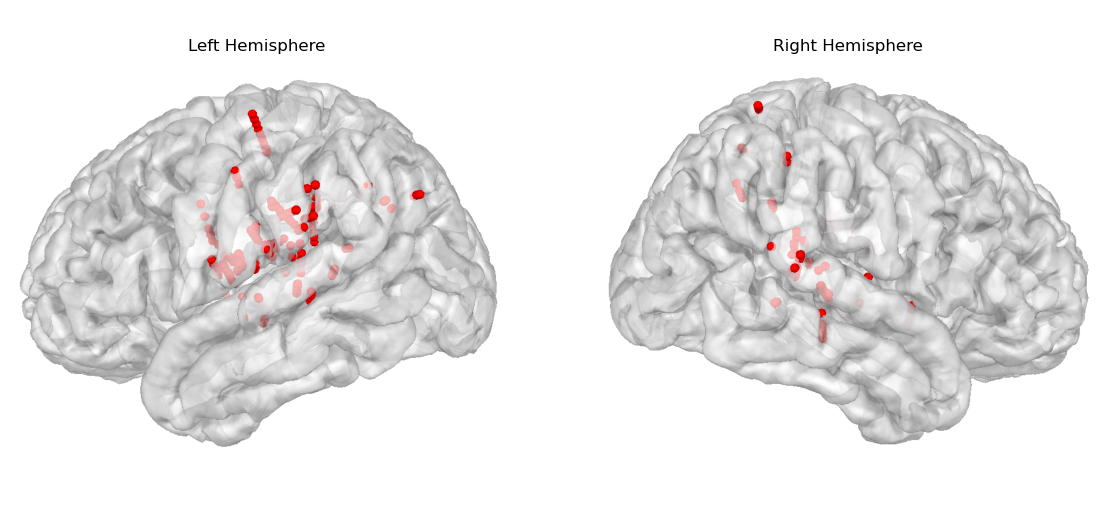

In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14,8))

brain.show_view('lateral', hemi='lh')
img_lh = brain.screenshot()
brain.show_view('lateral', hemi='rh')
img_rh = brain.screenshot()

ax1.imshow(img_lh)
ax1.axis('off')
ax1.set_title('Left Hemisphere', y=0.9)

ax2.imshow(img_rh)
ax2.axis('off')
ax2.set_title('Right Hemisphere', y=0.9)

plt.show()


## test

In [6]:
from ieeg.viz.mri import plot_on_average

subjects = ['D0028', 'D0040', 'D0042', 'D0049', 'D0052', 'D0055', 'D0064', 'D0068', 'D0069', 'D0075', 'D0079', 'D0084', 'D0092', 'D0095', 'D0096']
# subjects = ['D0028', 'D0040', 'D0042', 'D0049', 'D0052', 'D0055', 'D0064', 'D0068', 'D0069', 'D0075', 'D0079', 'D0084', 'D0092']
# subjects = ['D0028', 'D0040']
bids_root = Path("~/cworkspace/BIDS-1.4_Phoneme_sequencing/BIDS/").expanduser()
recon_dir = Path("~/cworkspace/ECoG_Recon_Full/").expanduser()


brain = plot_on_average(
    subjects,
    subj_dir=recon_dir,
    hemi='both',
    # picks=aud_picks_list,
    # picks=smc_picks_list,
    color='red',
    background='white',
    show=False,
    average='cvs_avg35_inMNI152',
    transparency=0.7,
    cortex=[(0.9, 0.9, 0.9), (0.7, 0.7, 0.7)],
)

# brain.show_view('lateral')
# brain._renderer.plotter.show(jupyter_backend='html')

QStandardPaths: XDG_RUNTIME_DIR not set, defaulting to '/tmp/runtime-zms14'
/hpc/home/zms14/repos/IEEG_Pipelines/ieeg/viz/mri.py:805: RuntimeWarning: Fiducial point lpa not found, assuming identity RAS (non-zero origin) to head transformation
  info.set_montage(montage)
/hpc/home/zms14/repos/IEEG_Pipelines/ieeg/viz/mri.py:805: RuntimeWarning: Fiducial point lpa not found, assuming identity RAS (non-zero origin) to head transformation
  info.set_montage(montage)
/hpc/home/zms14/repos/IEEG_Pipelines/ieeg/viz/mri.py:805: RuntimeWarning: Fiducial point lpa not found, assuming identity RAS (non-zero origin) to head transformation
  info.set_montage(montage)
/hpc/home/zms14/repos/IEEG_Pipelines/ieeg/viz/mri.py:805: RuntimeWarning: Fiducial point lpa not found, assuming identity RAS (non-zero origin) to head transformation
  info.set_montage(montage)
/hpc/home/zms14/repos/IEEG_Pipelines/ieeg/viz/mri.py:805: RuntimeWarning: Fiducial point lpa not found, assuming identity RAS (non-zero origin) 

In [7]:
brain._renderer.plotter.show(jupyter_backend='html')

KeyError: 'acc87de3ad4eda8bff8302ce6e69af9d_1099400L'

In [ ]:
brain.show_view('lateral', hemi='lh')
image = brain.screenshot()

plt.figure(figsize=(12, 8))
plt.imshow(image)
plt.axis("off")
plt.show()

KeyboardInterrupt: 

: 

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14,8))

brain.show_view('lateral', hemi='lh')
img_lh = brain.screenshot()
brain.show_view('lateral', hemi='rh')
img_rh = brain.screenshot()

ax1.imshow(img_lh)
ax1.axis('off')
ax1.set_title('Left Hemisphere', y=0.9)

ax2.imshow(img_rh)
ax2.axis('off')
ax2.set_title('Right Hemisphere', y=0.9)

plt.show()



: 